# Statement-first algorithm similarity study

This notebook reads immutable local receipts. The CF+AtCoder publisher-description
cohort is separate from the 24,297-row native metadata catalog. LeetCode text is
quarantined; AtCoder dataset rows without native IDs are not catalog joins.
Existing 3,647 judgments are AI-reviewed, not human gold. Unknown relevance is
never a negative. Compression neighbor preservation is not educational utility.


In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if ROOT.name == 'algorithm_system': ROOT=ROOT.parents[1]
assert (ROOT/'research/algorithm_system').is_dir()
R=ROOT/'research/algorithm_system'
RUN=ROOT/'private-learning/algorithm-system/statement-run-v1'
EVAL=ROOT/'private-learning/algorithm-system/statement-evaluation-v1'
COMP=ROOT/'private-learning/algorithm-system/compression-v1'
FIG=R/'figures'; FIG.mkdir(exist_ok=True)
manifest=json.loads((RUN/'manifest.json').read_text())
assert hashlib.sha256((RUN/'corpus.jsonl').read_bytes()).hexdigest()==manifest['corpus_sha256']
print('Native metadata catalog: 24,297 problems')
print('Publisher statement cohort:',manifest['count'],manifest['platforms'])
print('Native identity available:',manifest['native_identity_available'])
print('Native catalog matches:',manifest['catalog_matches'])
print('No model promotion:',manifest['no_model_promotion'])


Native metadata catalog: 24,297 problems
Publisher statement cohort: 9424 {'atcoder': 1323, 'codeforces': 8101}
Native identity available: 8097
Native catalog matches: 7077
No model promotion: True


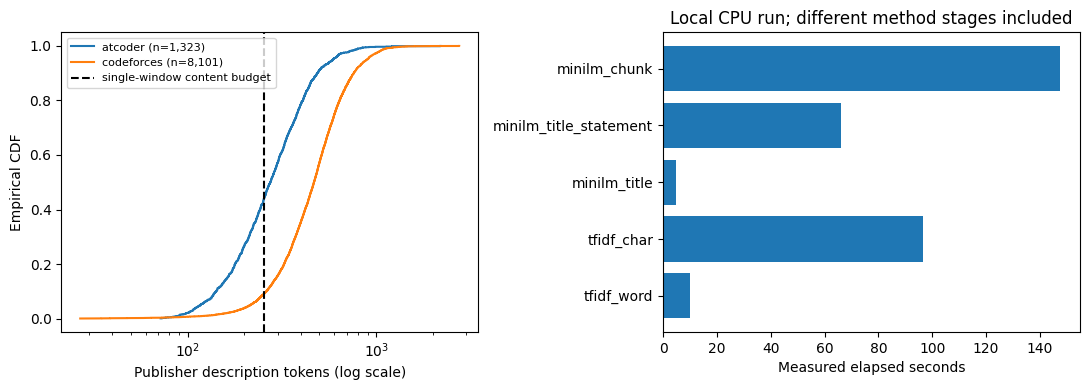

,method,seconds,shape,nonzero,outputs,queries,short_lists,encode_seconds,max_tokens,truncation,...,vector_bytes,chunks,window_content_tokens,overlap,aggregation,all_content_tokens_covered,statement_completeness,status,available_tagged_platforms,missing_tags_not_imputed
0,tfidf_word,10.049654,"[9424, 178480]",2867604.0,{'top10.jsonl': '82c1799fbef970b4399a4f6de3bf3...,9424.0,0.0,unavailable,unavailable,unavailable,...,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable
1,tfidf_char,96.408024,"[9424, 100000]",23552544.0,{'top10.jsonl': '7549422f310340149b3175ff23958...,9424.0,0.0,unavailable,unavailable,unavailable,...,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable
2,minilm_title,unavailable,unavailable,unavailable,{'top10.jsonl': '1d33e4630f402808fe4ab6b1fd0cf...,9424.0,0.0,3.457563,256.0,prefix beyond tokenizer limit,...,14475264.0,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable
3,minilm_title_statement,unavailable,unavailable,unavailable,{'top10.jsonl': '286e1126d8f11c86a569278485537...,9424.0,0.0,64.800701,256.0,prefix beyond tokenizer limit,...,14475264.0,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable
4,minilm_chunk,unavailable,unavailable,unavailable,{'top10.jsonl': '0913ab18bc6124799e9c9cacbf853...,9424.0,0.0,146.135388,unavailable,unavailable,...,14475264.0,22034.0,254.0,0.0,token-count weighted mean of normalized chunks...,True,publisher available description; section compl...,unavailable,unavailable,unavailable
5,tag_jaccard,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,...,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,blocked_no_cross_platform_matched_tag_coverage,{'codeforces': 7979},True
6,hierarchical_taxonomy,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,...,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,blocked_no_cross_platform_matched_tag_coverage,{'codeforces': 7979},True
7,hybrid,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,...,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,unavailable,blocked_no_cross_platform_matched_tag_coverage,{'codeforces': 7979},True


In [2]:
corpus=[json.loads(x) for x in (RUN/'corpus.jsonl').read_text().splitlines()]
lengths=json.loads((RUN/'token-lengths.json').read_text())
fig,axes=plt.subplots(1,2,figsize=(11,4))
for platform in sorted({r['platform'] for r in corpus}):
    values=sorted(lengths[i] for i,r in enumerate(corpus) if r['platform']==platform)
    axes[0].step(values,np.arange(1,len(values)+1)/len(values),where='post',label=f'{platform} (n={len(values):,})')
axes[0].axvline(254,color='black',linestyle='--',label='single-window content budget')
axes[0].set(xscale='log',xlabel='Publisher description tokens (log scale)',ylabel='Empirical CDF'); axes[0].legend(fontsize=8)
names=[k for k,v in manifest['methods'].items() if 'status' not in v]
secs=[manifest['methods'][k].get('encode_seconds',0)+manifest['methods'][k].get('seconds',0)+manifest['methods'][k].get('retrieval_seconds',0) for k in names]
axes[1].barh(names,secs);axes[1].set(xlabel='Measured elapsed seconds',title='Local CPU run; different method stages included')
fig.tight_layout();fig.savefig(FIG/'statement-baseline.png',dpi=160)
plt.show()
pd.DataFrame([{'method':k,**v} for k,v in manifest['methods'].items()]).fillna('unavailable')


In [3]:
print('Evaluation files:',sorted(p.name for p in EVAL.glob('*')))
for p in sorted(EVAL.glob('*.json')):
    obj=json.loads(p.read_text())
    print(p.name, json.dumps(obj,ensure_ascii=False)[:5000])
print('Interpretation: cross-platform native-ID overlap may have zero usable judgments.')
print('Do not interpret observed coverage, tag agreement, or neighbor overlap as learning gains.')


Evaluation files: ['evaluation.json']
evaluation.json {"ambiguous_duplicate_review_queue": {"items": [{"historical_ai_label": null, "method_ranks": {"minilm_chunk": 7, "minilm_title": 1, "minilm_title_statement": 1, "tfidf_char": 7, "tfidf_word": 1}, "platform_pair": "atcoder>codeforces", "query": "codecontests:802411c3010cb00d1b05bad57ca77365a3c699d6:train:train-00003-of-00039-e3822fccad6e083a.parquet:310", "status": "possible_semantic_overlap; human_duplicate_review_pending; no_merge_or_label", "target": "codeforces:975B"}, {"historical_ai_label": null, "method_ranks": {"minilm_chunk": 1, "minilm_title": 2, "minilm_title_statement": 2, "tfidf_char": 1, "tfidf_word": 2}, "platform_pair": "atcoder>codeforces", "query": "codecontests:802411c3010cb00d1b05bad57ca77365a3c699d6:train:train-00004-of-00039-cefe355b4667b27e.parquet:181", "status": "possible_semantic_overlap; human_duplicate_review_pending; no_merge_or_label", "target": "codeforces:1499F"}, {"historical_ai_label": null, "method

In [4]:
print('Compression receipts:',sorted(p.name for p in COMP.glob('*.json')))
for p in sorted(COMP.glob('*.json')):
    obj=json.loads(p.read_text())
    if isinstance(obj,dict): print(p.name,json.dumps(obj,ensure_ascii=False)[:12000])
print('Original 384D embeddings remain the reference; no automatic promotion.')


Compression receipts: ['receipt.json']
receipt.json {"baseline": {"corpus_sha256": "42e8cfe6042c34ddcd7a09e271dec98dec07e4f955616ead9ad8ebe911edef0b", "dimensions": 384, "method": "minilm_chunk", "top50_path": "minilm_chunk/top50.jsonl", "top50_sha256": "ae10bf99efd2b79b6425223402a7ea1ee62ffd98dd488632d905bfb551c6f419", "vector_sha256": "0113098f36a52da16b834dbdf85997f9f641874245315a9948eced1455ab8e0c"}, "comparison": "per-query TopK overlap only; neighborhood preservation is not relevance or recommendation quality", "environment": {"machine": "arm64", "numpy": "2.1.3", "python": "3.13.2"}, "ks": [10, 20, 50], "methods": {"original384": {"array_bytes": 14475264, "array_file_bytes": 14475392, "counts": {"queries": 9424, "short_lists": 0}, "dimensions": 384, "disk_bytes_total": 98534851, "fit_population": "none; original baseline vectors", "incremental_process_peak_rss_bytes": 28213248, "neighbor_overlap": {"top10": {"comparable_query_count": 9424, "mean_fraction": 1.0, "queries": 9424},

,method,dimensions,Top10 overlap,vector MiB,retrieval seconds
0,original384,384,1.000000,13.804688,0.490667
1,pca128,128,0.652472,4.601562,0.460417
2,pca256,256,0.679499,9.203125,0.470267
3,pca64,64,0.575202,2.300781,0.456964
4,rp128_seed17,128,0.467445,4.601562,0.467240
5,rp256_seed17,256,0.598376,9.203125,0.480670
6,rp64_seed17,64,0.324066,2.300781,0.458106
7,svd128,128,0.842763,4.601562,0.474493
8,svd256,256,0.973875,9.203125,0.482610
9,svd64,64,0.681335,2.300781,0.467162


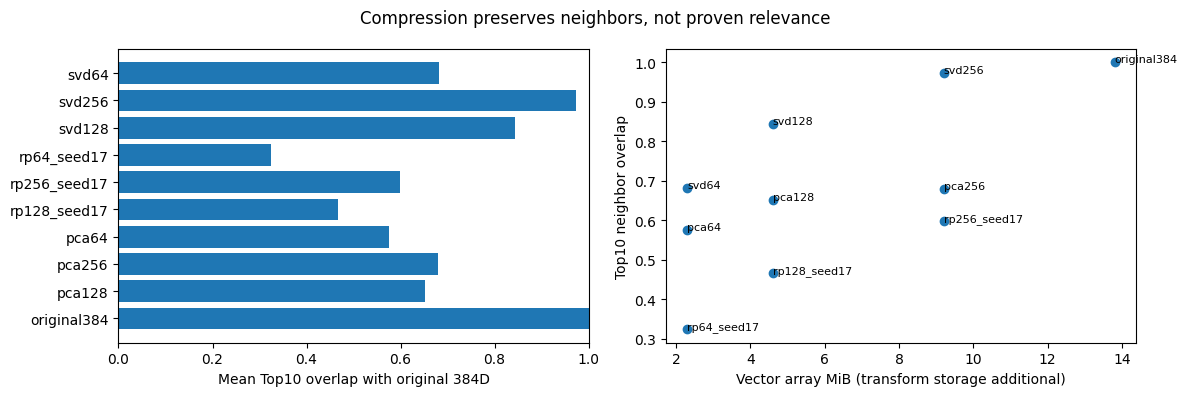

In [5]:
compression=json.loads((COMP/'receipt.json').read_text())
records=[]
for name,m in compression['methods'].items():
    if m.get('status')=='complete':
        records.append({'method':name,'dimensions':m['dimensions'],'Top10 overlap':m['neighbor_overlap']['top10']['mean_fraction'],'vector MiB':m['array_bytes']/2**20,'retrieval seconds':m['retrieval_seconds']})
table=pd.DataFrame(records)
display(table)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].barh(table['method'],table['Top10 overlap']);axes[0].set(xlim=(0,1),xlabel='Mean Top10 overlap with original 384D')
axes[1].scatter(table['vector MiB'],table['Top10 overlap'])
for _,r in table.iterrows():axes[1].annotate(r['method'],(r['vector MiB'],r['Top10 overlap']),fontsize=8)
axes[1].set(xlabel='Vector array MiB (transform storage additional)',ylabel='Top10 neighbor overlap')
fig.suptitle('Compression preserves neighbors, not proven relevance')
fig.tight_layout();fig.savefig(FIG/'compression-ablation.png',dpi=160);plt.show()


## Reproducibility and limits

See `CHECKPOINT1.md`, `CHECKPOINT2.md`, `REPORT.md`, source receipts, model manifest,
and private run manifests for hashes and source conditions. Measured runtime and
peak RSS describe this local machine, not OCI feasibility. Native difficulty
percentiles summarize different populations and are provisional across platforms.
No supervised difficulty calibration or relevance model was fitted. Human-review
queues are unlabelled deliverables requiring future adjudication. New statements
are kept private; this notebook exports aggregate figures, not statement mirrors.
